# BM25 + география: мягкое переранжирование

Четыре варианта: текст; совпадение локаций; расстояние; оба сигнала. BM25 ищет по заголовкам без лемматизации, как в соседнем эксперименте. Корпус — уникальные объявления всего train.parquet, включая объявления отложенных взаимодействий; для повторяющегося ID берём последнюю строку файла. Это фиксированный доступный каталог, а связи отложенных запросов используются только для оценки.

Сплит по нормализованному тексту запроса из src.split. На 500 случайных контекстах val выбираем параметры каждого варианта, затем оцениваем на 500 контекстах test. Центры локаций — медианы координат уникальных объявлений только train-части. Это приближённые центры, не координаты пользователя.

Метрика — макро Recall@50 по уникальным наблюдаемым item_id каждого полного контекста. Запросы без выдачи получают 0. Разметка релевантности неполная; выводы относятся к этому локальному эксперименту.

In [1]:
from pathlib import Path
import sys
import gc
from itertools import product

import numpy as np
import pandas as pd
import polars as pl
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/split.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.split import split_queries
from src.retrievers.bm25 import BM25Retriever

SEED = 42
N_QUERIES = 500  # для каждой из val/test; увеличивается при необходимости
K = 50
POOLS = [100, 300, 1000, 3000]
WEIGHTS = [0.05, 0.1, 0.2]
TAUS = [5, 20, 100]  # километры
QUERY_COLS = ["search_query", "search_location_id", "search_is_delivery_search", "search_infm_params_text", "search_category"]
ITEM_COLS = ["item_id", "item_title_raw", "item_location_id", "item_latitude", "item_longitude"]

## Данные и центры локаций

In [2]:
data = pl.read_parquet(ROOT / "data/train.parquet", columns=list(dict.fromkeys(QUERY_COLS + ITEM_COLS)))
data = data.with_columns(
    pl.Series("split", split_queries(data["search_query"], seed=SEED)),
    pl.col("item_latitude", "item_longitude").cast(pl.Float64),
)
items = pd.DataFrame(data.select(ITEM_COLS).unique(subset="item_id", keep="last", maintain_order=True).sort("item_id").to_dict(as_series=False))
train_items = data.filter(pl.col("split") == "train").unique(subset="item_id", keep="last", maintain_order=True)
centers = train_items.filter(
    pl.col("item_latitude").is_between(-90, 90) & pl.col("item_longitude").is_between(-180, 180)
).group_by("item_location_id").agg(
    pl.col("item_latitude").median().alias("center_lat"),
    pl.col("item_longitude").median().alias("center_lon"),
    pl.len().alias("center_items"),
)
centers = pd.DataFrame(centers.to_dict(as_series=False)).set_index("item_location_id")
queries, targets = {}, {}
for split in ["val", "test"]:
    part = data.filter(pl.col("split") == split).group_by(QUERY_COLS).agg(pl.col("item_id").unique().alias("targets")).sort(QUERY_COLS)
    part = part.sample(n=min(N_QUERIES, part.height), seed=SEED, shuffle=True)
    queries[split] = pd.DataFrame(part.select(QUERY_COLS).to_dict(as_series=False)).join(centers, on="search_location_id")
    targets[split] = [set(ids) for ids in part["targets"].to_list()]
    assert all(targets[split])
    assert set().union(*targets[split]).issubset(set(items.item_id))
    print(split, "контекстов:", len(part), "без центра:", queries[split].center_lat.isna().sum())
print("Объявлений в корпусе:", len(items), "центров:", len(centers))
del data, train_items
gc.collect();

val контекстов: 500 без центра: 67
test контекстов: 500 без центра: 52
Объявлений в корпусе: 344825 центров: 2476


## BM25 и признаки кандидатов

Один индекс и топ-3000 на запрос. Меньшие пулы — его префиксы; BM25 нормируем по максимальному скору запроса. Нулевые текстовые совпадения не добавляем. Неизвестное расстояние даёт нулевой геобонус.

In [3]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

model = BM25Retriever(lemmatize=False, batch_size=16).fit(items[["item_id", "item_title_raw"]])
metadata = items.set_index("item_id")
features = {}
for split in ["val", "test"]:
    q = queries[split]
    shape = (len(q), max(POOLS))
    f = {
        "text": np.full(shape, -np.inf, dtype=np.float32),
        "same": np.zeros(shape, dtype=np.float32),
        "distance": np.full(shape, np.inf, dtype=np.float32),
        "hit": np.zeros(shape, dtype=bool),
        "denom": np.array([len(t) for t in targets[split]]),
    }
    for start in range(0, len(q), 32):
        candidates = model.retrieve(q.iloc[start:start + 32], k=max(POOLS))
        for local_i, group in candidates.groupby("query_index", sort=False):
            i = start + int(local_i)
            group = group.sort_values("rank")
            ids = group.item_id.to_numpy()
            count = len(ids)
            item = metadata.loc[ids]
            scores = group.score.to_numpy()
            f["text"][i, :count] = scores / scores.max()
            f["same"][i, :count] = (item.item_location_id.to_numpy() == q.iloc[i].search_location_id)
            distance = haversine(q.iloc[i].center_lat, q.iloc[i].center_lon, item.item_latitude.to_numpy(), item.item_longitude.to_numpy())
            valid = np.isfinite(distance) & item.item_latitude.between(-90, 90).to_numpy() & item.item_longitude.between(-180, 180).to_numpy()
            f["distance"][i, :count] = np.where(valid, distance, np.inf)
            f["hit"][i, :count] = [item_id in targets[split][i] for item_id in ids]
    features[split] = f
    print(split, "готово; без кандидатов:", (~np.isfinite(f["text"]).any(axis=1)).sum())
del model, metadata, candidates
gc.collect();

val готово; без кандидатов: 1
test готово; без кандидатов: 2


## Подбор на val

`score = text + alpha * same_location + beta * exp(-distance / tau)`. При равенстве скоров сохраняем порядок исходного BM25. Проверяем покрытие пула Recall@N отдельно от качества топ-50.

In [4]:
def recall(f, n, alpha=0, beta=0, tau=20):
    scores = f["text"][:, :n] + alpha * f["same"][:, :n]
    if beta:
        scores = scores + beta * np.exp(-f["distance"][:, :n] / tau)
    top = np.argsort(-scores, axis=1, kind="stable")[:, :K]
    return np.take_along_axis(f["hit"][:, :n], top, axis=1).sum(axis=1) / f["denom"]

coverage = pd.DataFrame([
    {"split": split, "N": n, "Recall@N": (f["hit"][:, :n].sum(axis=1) / f["denom"]).mean()}
    for split, f in features.items() for n in POOLS
])
display(coverage)

configs = [("BM25", 0, 0, 20)]
configs += [("location", a, 0, 20) for a in WEIGHTS]
configs += [("distance", 0, b, t) for b, t in product(WEIGHTS, TAUS)]
configs += [("both", a, b, t) for a, b, t in product(WEIGHTS, WEIGHTS, TAUS)]
rows = []
for n in POOLS:
    for variant, alpha, beta, tau in configs:
        rows.append({"variant": variant, "N": n, "alpha": alpha, "beta": beta, "tau": tau,
                     "val_recall": recall(features["val"], n, alpha, beta, tau).mean()})
validation = pd.DataFrame(rows)
# При равных метриках выбираем меньший пул и меньшие веса.
best = validation.sort_values(["val_recall", "N", "alpha", "beta", "tau"], ascending=[False, True, True, True, True]).drop_duplicates("variant").set_index("variant").loc[["BM25", "location", "distance", "both"]].reset_index()
display(best)
display(validation.pivot_table(index="N", columns="variant", values="val_recall", aggfunc="max"))

,split,N,Recall@N
0,val,100,0.233667
1,val,300,0.319067
2,val,1000,0.439967
3,val,3000,0.551767
4,test,100,0.210149
5,test,300,0.309706
6,test,1000,0.444978
7,test,3000,0.556735


,variant,N,alpha,beta,tau,val_recall
0,BM25,100,0.0,0.0,20,0.168667
1,location,3000,0.2,0.0,20,0.311967
2,distance,3000,0.0,0.2,100,0.311967
3,both,3000,0.2,0.2,100,0.416100


variant,BM25,both,distance,location
N,,,,
100,0.168667,0.215667,0.215667,0.208667
300,0.168667,0.289067,0.267067,0.260067
1000,0.168667,0.365300,0.300967,0.295967
3000,0.168667,0.416100,0.311967,0.311967


## Проверка выбранных настроек на test

Настройки каждого варианта уже зафиксированы по val. Test не используется для выбора весов, масштаба или размера пула. Разница считается относительно чистого BM25 на тех же контекстах.

Центр известен контекстов: 448
Центр неизвестен контекстов: 52


,variant,N,alpha,beta,tau,val_recall,test_recall,delta_test
0,BM25,100,0.0,0.0,20,0.168667,0.153968,0.000000
1,location,3000,0.2,0.0,20,0.311967,0.300154,0.146187
2,distance,3000,0.0,0.2,100,0.311967,0.301297,0.147329
3,both,3000,0.2,0.2,100,0.416100,0.432716,0.278748


BM25        0.140589
location    0.303743
distance    0.305019
both        0.451692
Name: Recall@50, dtype: float64

BM25        0.269231
location    0.269231
distance    0.269231
both        0.269231
Name: Recall@50, dtype: float64

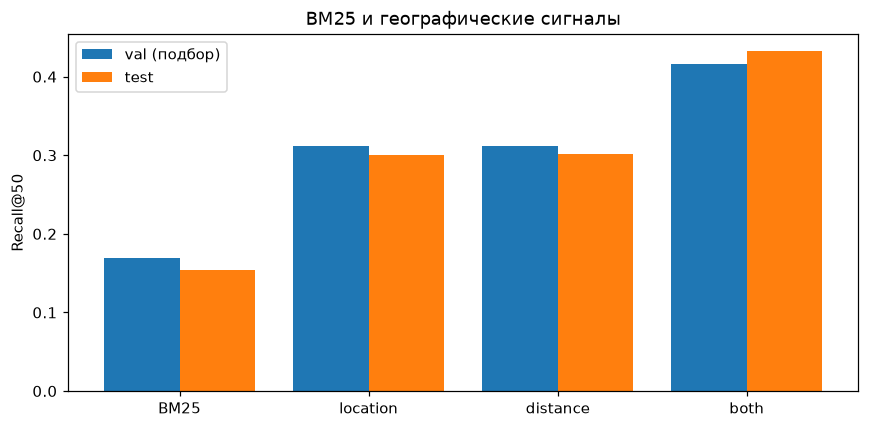

In [5]:
test_recalls = {}
for row in best.itertuples(index=False):
    test_recalls[row.variant] = recall(features["test"], int(row.N), row.alpha, row.beta, row.tau)
comparison = best.copy()
comparison["test_recall"] = [test_recalls[v].mean() for v in comparison.variant]
comparison["delta_test"] = comparison.test_recall - test_recalls["BM25"].mean()
display(comparison)

missing_center = queries["test"].center_lat.isna().to_numpy()
for label, mask in [("Центр известен", ~missing_center), ("Центр неизвестен", missing_center)]:
    if mask.any():
        print(label, "контекстов:", mask.sum())
        display(pd.Series({v: r[mask].mean() for v, r in test_recalls.items()}, name="Recall@50"))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
positions = np.arange(len(comparison))
ax.bar(positions - 0.2, comparison.val_recall, width=0.4, label="val (подбор)")
ax.bar(positions + 0.2, comparison.test_recall, width=0.4, label="test")
ax.set_xticks(positions, comparison.variant)
ax.set(ylabel="Recall@50", title="BM25 и географические сигналы")
ax.legend()
fig.tight_layout()
plt.show()

## Наблюдения по запуску

| Вариант | Recall@50 val | Recall@50 test | Параметры, выбранные на val |
|---|---:|---:|---|
| BM25 | 0.1687 | 0.1540 | N=100 (топ-50 одинаков для всех N) |
| Совпадение локации | 0.3120 | 0.3002 | N=3000, alpha=0.2 |
| Расстояние | 0.3120 | 0.3013 | N=3000, beta=0.2, tau=100 км |
| Комбинация | 0.4161 | 0.4327 | N=3000, alpha=beta=0.2, tau=100 км |

География помогает восстановлению наблюдаемых пар на этой выборке. Покрытие BM25 Recall@3000 на test — 0.5567; переранжирование не может вернуть отсутствующие в пуле объявления. Оптимальные параметры лежат на верхних границах проверенной сетки, поэтому насыщение по пулу и весам пока не установлено.

Комбинация получает до 0.4 геобонуса, одиночные признаки — до 0.2. Для вывода именно о взаимодополняемости сигналов нужен дополнительный эксперимент с одинаковым суммарным бюджетом геовесов. Здесь сравниваются согласованные четыре формулы и заданная сетка.

У 52 из 500 тестовых контекстов неизвестен центр. В этой группе все четыре варианта дали Recall@50=0.2692. Это не повод удалять их из оценки.

Результаты предварительные: 500 контекстов val и 500 test, текстовый вход ограничен заголовком. Настройки не следует автоматически переносить на другие текстовые поля или на бенчмарк с иным распределением запросов.